<div style="text-align: center; line-height: 1.8;">

<h3>Assessment - 2</h3>

<h2><b>Extracting Insights from Counselling Dialogue Data</b></h2>

<br>
<div style="text-align: center;">
    <img src="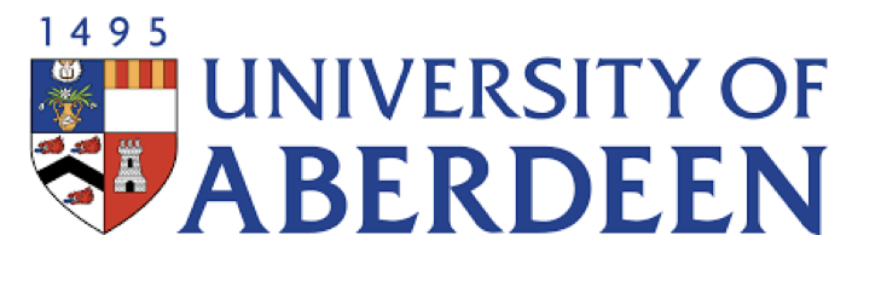" width="400"/>
    <br><br><br>

<h3><b>MSc ROBOTICS AND ARTIFICIAL INTELLIGENCE</b><br>
University of Aberdeen</h3>


<h3><b>Data Mining With Deep Learning - CS552J</b></h3>

<br>
<div style="text-align: center;">
    <h3><b>Group 12</b><br>
        KAUSHIK IYER <br>
        KAILASH RAM JAYARAM</h3>

<br><br>

<h3>MAY 2026</ph3>

</div>

# 1. Introduction

This report presents a comprehensive analysis of the AnnoMI counselling dialogue dataset, undertaken as part of Assessment 2 for the CS552J Data Mining with Deep Learning module at the University of Aberdeen. The AnnoMI dataset contains transcribed utterances from real-world Motivational Interviewing (MI) therapy sessions, annotated with speaker role, therapist behaviour type, client talk type, and session quality indicators. It provides a rich, naturalistic corpus for applying natural language processing (NLP) and machine learning techniques to a clinically meaningful domain.

Motivational Interviewing is a well-established, evidence-based counselling method designed to help individuals resolve ambivalence and build motivation for behaviour change. Central to MI practice are specific therapist communicative behaviours, such as reflective listening, open-ended questioning, affirming, and summarising, which are associated with improved client outcomes. Automatically classifying these behaviours from transcribed sessions has significant practical value: it could support therapist training, enable scalable session quality monitoring, and inform the development of real-time clinical decision support systems.

The dataset comprises 9,699 utterances drawn from 134 transcripts, labelled across 11 columns including *interlocutor* (therapist or client), *main_therapist_behaviour* (four categories), *client_talk_type* (three categories), and *mi_quality* (high or low). The primary analytical objective of this assessment is to explore and characterise the dataset, extract meaningful thematic summaries, and develop supervised classifiers capable of automatically predicting therapist behaviour from utterance text.

This report is structured as follows:

- **Section 2** provides a theoretical background covering preprocessing strategies, feature extraction methods, deep learning approaches, and evaluation frameworks.
- **Section 3** presents exploratory data analysis, including summary statistics and visualisations derived directly from the notebook.
- **Section 4** describes the frequency-based summarisation applied to each therapist behaviour type.
- **Section 5** details the two classifiers trained: Logistic Regression with TF-IDF and a BERT-based transformer, and provides an in-depth comparative analysis.
- **Section 6** reports full model performance using exact metrics obtained from the held-out test set.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import nltk
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer , CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer
from transformers import BertForSequenceClassification
import torch
from torch.utils.data import DataLoader, Dataset
from torch.optim import AdamW


import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# 2. Task 1: Description of Data and Methods

## 2.1 Preprocessing Steps

Raw text data cannot be fed directly into machine learning models and must first be transformed into clean, structured numerical representations. The preprocessing pipeline implemented in this project comprises several sequential steps.

**Tokenisation** splits raw utterances into discrete units (tokens) using NLTK's `word_tokenize` function, which handles word boundaries, contractions, and punctuation correctly.

**Lowercasing** ensures consistent treatment of semantically identical tokens regardless of capitalisation (e.g., *"Therapy"* and *"therapy"* become the same token).

**Punctuation removal** strips non-alphabetic characters that carry no semantic value in a bag-of-words representation.

**Stopword removal** eliminates high-frequency function words such as *"the"*, *"is"*, and *"and"* using NLTK's English stopword corpus. These tokens are highly common across all classes and reduce the discriminative signal-to-noise ratio for traditional models.

The `clean_text` function defined in the notebook applies all four steps in sequence, producing a normalised string suitable for TF-IDF vectorisation.

For the BERT-based classifier, a distinct preprocessing pathway was used. The DistilBERT tokeniser (`distilbert-base-uncased`) handles tokenisation into subword units via WordPiece encoding, retains stopwords (as contextual models benefit from grammatical function words), and applies truncation and padding to a maximum sequence length of 64 tokens to produce fixed-size input tensors compatible with the transformer architecture.

---

## 2.2 Feature Extraction Methods

Before modelling, feature extraction converts processed text into numerical representations that capture meaningful information about the data.

Basic count-based features were computed during exploratory analysis:

- **Utterance length** (number of whitespace-delimited words) was derived from `utterance_text` and used both as a descriptive statistic and as a variable for significance testing between session quality groups.
- **Part-of-speech (POS) tagging** using NLTK's averaged perceptron tagger assigns grammatical labels to each token, enabling structural analysis of speech differences between therapists and clients.

### TF-IDF Vectorisation

TF-IDF (Term Frequency-Inverse Document Frequency) vectorisation was the primary feature extraction method for classification.

It weights each term by its importance to a specific utterance relative to the entire corpus, suppressing common words and amplifying class-distinctive vocabulary.

The `TfidfVectorizer` was configured with:

- `max_features=5000` to limit vocabulary size
- `ngram_range=(1,2)` to capture informative bigrams (e.g., *"tell me"*, *"how do"*) alongside unigrams

This produced a sparse **7,761 × 5,000** training matrix used directly by the Logistic Regression classifier.

---

## 2.3 Deep Learning Approaches and Trade-Offs

Several deep learning architectures have been applied to text classification.

### Recurrent Neural Networks (RNNs)

Recurrent Neural Networks (RNNs), particularly **Long Short-Term Memory (LSTM)** networks, model sequential dependencies and were the dominant NLP architecture prior to 2018. However, LSTMs are slow to train and struggle to capture long-range dependencies.

### Convolutional Neural Networks (CNNs)

Convolutional Neural Networks (CNNs) applied to text efficiently capture local n-gram patterns but lack global context modelling.

### Transformer-Based Models

Transformer-based models introduced by Vaswani et al. (2017) overcome these limitations through self-attention mechanisms that process the entire input sequence in parallel and capture bidirectional contextual dependencies.

In this project, `BertForSequenceClassification` (using the `bert-base-uncased` backbone) was fine-tuned using DistilBERT tokenisation. DistilBERT retains approximately **97%** of BERT's performance while being **60% smaller** and **40% faster**, an important practical consideration given the computational constraints of the training environment.

Several important trade-offs were identified:

1. **Dataset Size**  
   BERT requires sufficient labelled examples per class for effective fine-tuning. The minority class, *therapist_input* (`n = 614`), limits the model's ability to learn highly robust representations.

2. **Computational Cost**  
   BERT training required significantly longer training time and substantially greater computational resources compared to Logistic Regression.

3. **Interpretability**  
   Logistic Regression provides interpretable coefficients that directly map to TF-IDF features, whereas BERT's internal attention mechanisms provide only indirect and less transparent feature attribution.

4. **Sequence Truncation**  
   The `max_length = 64` setting truncates utterances longer than 64 subword tokens. This may disproportionately affect the minority class, whose utterances tend to be longer and more information-dense.

---
## 2.4 Evaluation Strategies

Classification performance was measured using:

- **Precision**
- **Recall**
- **F1-Score**
- **Overall Accuracy**

### Evaluation Metrics

**Precision** measures the fraction of predicted positives that are genuinely positive.

**Recall** measures the fraction of actual positives correctly identified.

**F1-Score** is the harmonic mean of Precision and Recall, penalising models that optimise one metric at the expense of the other.

Given the substantial class imbalance, particularly the dominance of *other* (`n = 1,586`) over *therapist_input* (`n = 614`), **macro-averaged F1-score** was used as the primary evaluation metric. Macro averaging weights all four classes equally regardless of frequency, making it more suitable for imbalanced multiclass classification.

Although **Accuracy** is also reported, it must be interpreted cautiously because high accuracy can still occur even when minority classes are poorly predicted.

### Confusion Matrix Analysis

Confusion matrices were used to provide a per-class breakdown of:

- True Positives (TP)
- False Positives (FP)
- False Negatives (FN)

This analysis revealed which therapist behaviour categories were most frequently confused by the models.

### Error Analysis

Qualitative error analysis was conducted by manually inspecting misclassified utterances to better understand the linguistic characteristics associated with model failure.

### Statistical Testing

A **two-sample Welch’s t-test** was applied to determine whether the difference in utterance length between **high-quality** and **low-quality** MI sessions was statistically significant.

In [21]:
couns_dia =  pd.read_csv("/content/dataset.csv")
print(couns_dia.shape)
print(couns_dia.columns.tolist())
print(couns_dia.head())

(9699, 11)
['transcript_id', 'mi_quality', 'video_title', 'video_url', 'topic', 'utterance_id', 'interlocutor', 'timestamp', 'utterance_text', 'main_therapist_behaviour', 'client_talk_type']
   transcript_id mi_quality                               video_title  \
0              0       high  NEW VIDEO: Brief intervention: "Barbara"   
1              0       high  NEW VIDEO: Brief intervention: "Barbara"   
2              0       high  NEW VIDEO: Brief intervention: "Barbara"   
3              0       high  NEW VIDEO: Brief intervention: "Barbara"   
4              0       high  NEW VIDEO: Brief intervention: "Barbara"   

                                     video_url                         topic  \
0  https://www.youtube.com/watch?v=PaSKcfTmFEk  reducing alcohol consumption   
1  https://www.youtube.com/watch?v=PaSKcfTmFEk  reducing alcohol consumption   
2  https://www.youtube.com/watch?v=PaSKcfTmFEk  reducing alcohol consumption   
3  https://www.youtube.com/watch?v=PaSKcfTmFEk  re

# 3. Dataset Summary Statistics

The dataset was loaded from a CSV file and inspected across its 11 columns. The four primary columns of interest are:

- `interlocutor`
- `utterance_text`
- `main_therapist_behaviour`
- `client_talk_type`

Utterance length was computed by counting whitespace-delimited tokens in the `utterance_text` string.

---

## Table 1: Descriptive Statistics — Utterance Length (Word Count)

| Statistic | Value |
|---|---|
| Mean | 15.82 words |
| Median (50th %) | 9.00 words |
| Standard Deviation | 20.34 words |
| Minimum | 1 word |
| Maximum | 246 words |
| 25th Percentile | 2.00 words |
| 75th Percentile | 21.00 words |

The large gap between the **mean (15.82)** and **median (9.00)** confirms a strongly right-skewed distribution. Most utterances are short the 25th percentile is just 2 words, while a long tail of verbose turns pulls the mean upward.

The maximum value of **246 words** represents an unusually extended therapist or client turn. The interquartile range (IQR) of **19 words** (2–21) indicates that the central 50% of utterances fall within a relatively concise range.

This skew justifies reporting the median alongside the mean and motivates potential log-transformation of utterance length if used as a modelling feature.

---

## Table 2: Categorical Column Distributions

| Column | Categories | Counts | Imbalance Note |
|---|---|---|---|
| `interlocutor` | therapist / client | 4,882 / 4,817 | Near-balanced |
| `main_therapist_behaviour` | other / question / reflection / therapist_input | 1,586 / 1,386 / 1,296 / 614 | Moderate imbalance |
| `client_talk_type` | neutral / change / sustain | 3,102 / 1,174 / 541 | Strong imbalance |
| `mi_quality` | high / low | Not directly counted | Session-level quality label |

The `interlocutor` column is near-balanced (*therapist = 4,882*; *client = 4,817*), enabling reliable comparisons between speaker groups.

The `main_therapist_behaviour` column shows moderate imbalance. The *other* category is the most frequent (`n = 1,586`), while *therapist_input* is less than half as frequent (`n = 614`). This imbalance directly impacts classifier performance on the minority class, as reflected in the lower F1-scores reported in Section 6.

The `client_talk_type` distribution is more severely skewed, with *neutral* accounting for approximately **62%** of client utterances (`3,102` of `4,817`). This reflects the predominantly conversational character of therapy sessions, in which explicit change talk or sustain talk events occur relatively infrequently.

In [22]:
print(couns_dia.describe())
couns_dia['utterance_length'] = couns_dia['utterance_text'].astype(str).apply(lambda x:len(x.split()))
smy = couns_dia['utterance_length'].agg(['mean','median', 'min', 'std', 'max', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
smy.index = ['mean', 'median', 'min', 'std', 'max', '25%', '75%']
print(smy)
for col in['interlocutor', 'main_therapist_behaviour', 'client_talk_type', 'timestamp']:
    print(f"\n--{col} ---")
    print(couns_dia[col].value_counts())

       transcript_id  utterance_id
count    9699.000000   9699.000000
mean       71.834828     84.341891
std        38.474008    101.072809
min         0.000000      0.000000
25%        38.000000     19.000000
50%        71.000000     46.000000
75%       104.000000    110.000000
max       133.000000    597.000000
mean       15.819672
median      9.000000
min         1.000000
std        20.341819
max       246.000000
25%         2.000000
75%        21.000000
Name: utterance_length, dtype: float64

--interlocutor ---
interlocutor
therapist    4882
client       4817
Name: count, dtype: int64

--main_therapist_behaviour ---
main_therapist_behaviour
other              1586
question           1386
reflection         1296
therapist_input     614
Name: count, dtype: int64

--client_talk_type ---
client_talk_type
neutral    3102
change     1174
sustain     541
Name: count, dtype: int64

--timestamp ---
timestamp
00:01:40    31
00:00:57    31
00:02:28    31
00:02:02    29
00:01:51    29
        

# 4. Data Visualisation

Four visualisations were produced to explore the dataset across multiple dimensions. Each plot is reproduced below together with a detailed interpretation of the observed patterns and their implications for subsequent modelling and analysis.

In [47]:
import string

def clean_text(text):
    text = str(text).lower()  # Convert to string and lowercase
    text = ''.join([char for char in text if char not in string.punctuation]) # Remove punctuation
    tokens = word_tokenize(text)  # Tokenize
    tokens = [word for word in tokens if word not in stopwords.words('english')] # Remove stopwords
    return ' '.join(tokens)

# Display before and after cleaning examples
print("Original text example:", couns_dia['utterance_text'].iloc[0])
cleaned_example = clean_text(couns_dia['utterance_text'].iloc[0])
print("Cleaned text example:", cleaned_example)

couns_dia['cleaned_utterance_text'] = couns_dia['utterance_text'].apply(clean_text)
print("\nFirst 5 cleaned utterances:")
print(couns_dia['cleaned_utterance_text'].head())

Original text example: Thanks for filling it out. We give this form to everyone once a year regardless of why they come in. It helps us provide better care. Is it okay if I take a look at what you put down?
Cleaned text example: thanks filling give form everyone year regardless come helps us provide better care okay take look put

First 5 cleaned utterances:
0    thanks filling give form everyone year regardl...
1                                                 sure
2    lets see looks put drink alcohol least four ti...
3                                                mmhmm
4                      usually three four drinks drink
Name: cleaned_utterance_text, dtype: object


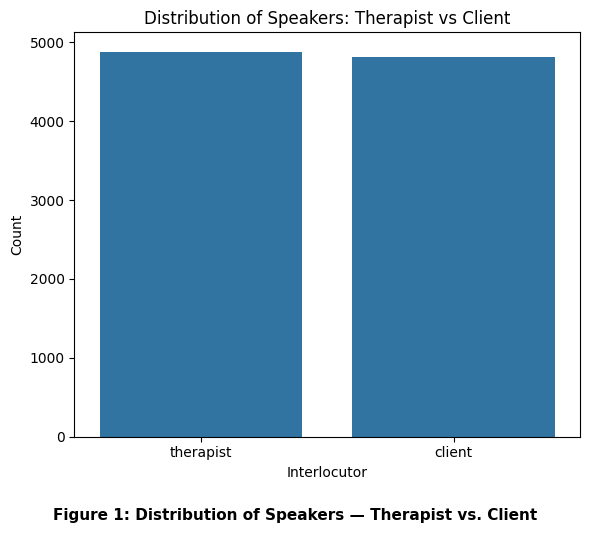

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.countplot(data=couns_dia, x='interlocutor')

plt.title('Distribution of Speakers: Therapist vs Client')
plt.xlabel('Interlocutor')
plt.ylabel('Count')

# Add figure caption at the bottom
plt.figtext(
    0.5,                     # x position
    -0.05,                   # y position
    'Figure 1: Distribution of Speakers — Therapist vs. Client',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Figure 1: Distribution of Speakers — Therapist vs. Client

The speaker distribution is highly balanced, with therapist utterances (`n = 4,882`) only slightly exceeding client utterances (`n = 4,817`). This near-equal representation is advantageous for comparative linguistic analysis because it reduces sampling bias between speaker groups.

From a modelling perspective, balanced speaker representation ensures that downstream analyses such as part-of-speech comparisons, utterance length analysis, and behavioural classification are not dominated by one interlocutor category. The result also reflects the turn-taking structure typical of counselling dialogue, where interaction is conversational rather than monologic.

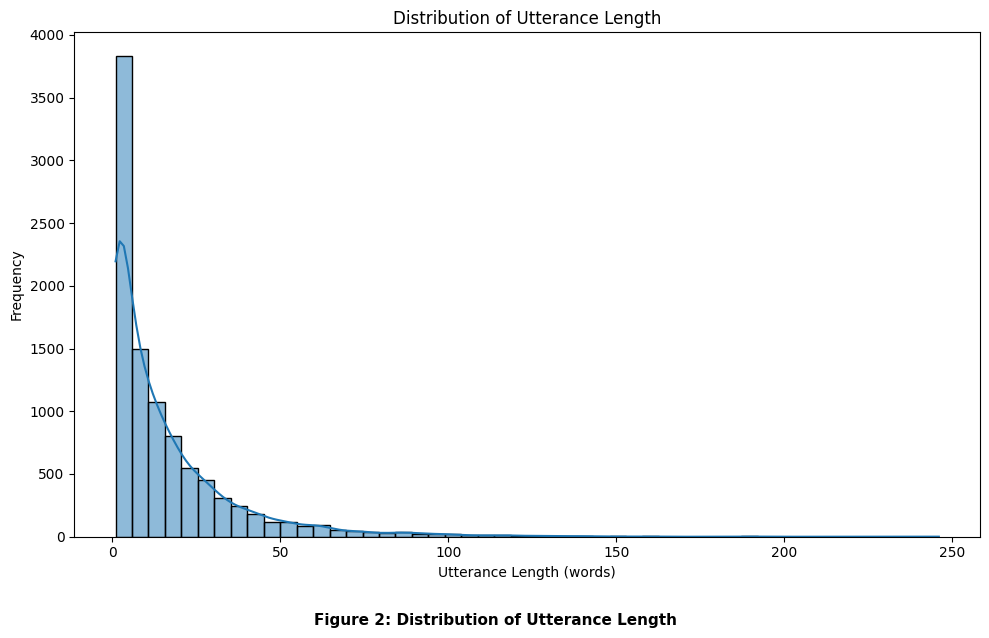

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

couns_dia = pd.read_csv("/content/dataset.csv")

couns_dia['utterance_length'] = couns_dia['utterance_text'].astype(str).apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(10, 6))

sns.histplot(couns_dia['utterance_length'], bins=50, kde=True)

plt.title('Distribution of Utterance Length')
plt.xlabel('Utterance Length (words)')
plt.ylabel('Frequency')

# Figure caption at bottom
plt.figtext(
    0.5,
    -0.05,
    'Figure 2: Distribution of Utterance Length',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Figure 2: Distribution of Utterance Length

Figure 2 illustrates the pronounced right-skewed distribution of utterance length, consistent with the descriptive statistics presented in Table 1.

The majority of utterances cluster between **1 and 30 words**, with the distribution peaking around **5–10 words**. The Kernel Density Estimation (KDE) curve further confirms the existence of a long right tail, with a small number of utterances extending beyond **100 words**.

This distribution is characteristic of spontaneous spoken dialogue, where short conversational responses, affirmations, and backchannels (e.g., *"Sure"*, *"Mm-hmm"*) occur far more frequently than extended explanations or narratives.

The long-tail region primarily corresponds to:

- Therapist summaries
- Psychoeducational explanations
- Extended client narratives

Understanding this distribution is important for model design decisions. In the BERT-based pipeline, sequence truncation at `max_length = 64` tokens affects only a relatively small proportion of utterances located in the extreme right tail, while the majority of samples remain fully preserved within the model’s input limit.

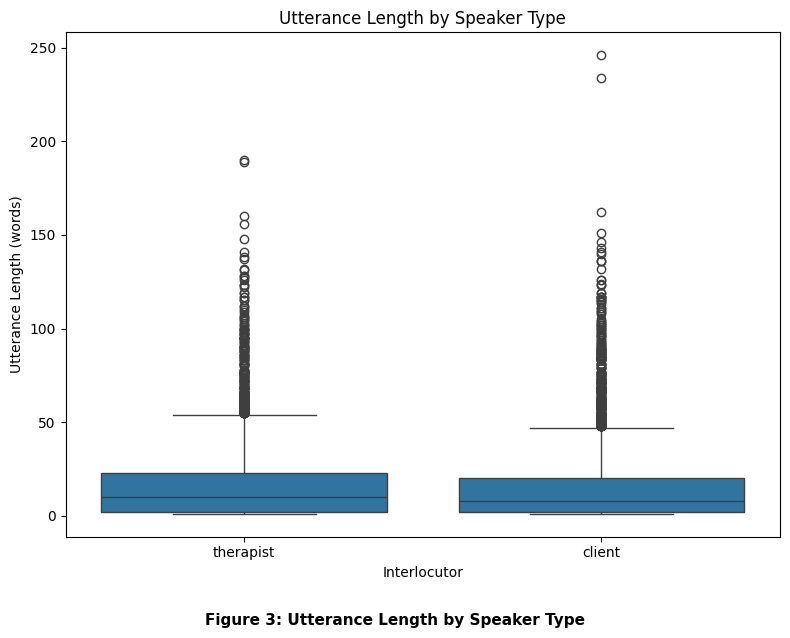

In [60]:
couns_dia['utterance_length'] = couns_dia['utterance_text'].astype(str).apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8,6))

sns.boxplot(
    data=couns_dia,
    x='interlocutor',
    y='utterance_length'
)

plt.title('Utterance Length by Speaker Type')
plt.xlabel('Interlocutor')
plt.ylabel('Utterance Length (words)')

# Figure caption at bottom
plt.figtext(
    0.5,
    -0.05,
    'Figure 3: Utterance Length by Speaker Type',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Figure 3: Utterance Length by Speaker Type

Figure 3 shows that both therapists and clients exhibit broadly similar median utterance lengths, approximately within the **8–12 word** range. However, therapist utterances display a wider interquartile range and greater variability overall.

Both speaker groups exhibit strongly right-skewed distributions with numerous outliers extending beyond the upper whisker. Therapist utterances contain many long-form responses associated with reflective summaries and psychoeducational explanations, while client utterances include several exceptionally long narrative responses, including one notable outlier approaching **250 words**.

To further investigate conversational characteristics, a **Welch’s independent two-sample t-test** was conducted comparing utterance length between **high-quality** and **low-quality** MI sessions:

- **t-statistic:** `-5.1575`
- **p-value:** `< 0.0001`

Because the p-value is substantially below the standard significance threshold (`p < 0.05`), the null hypothesis of equal mean utterance length is rejected.

This result indicates that session quality is significantly associated with utterance length, with **low-quality sessions exhibiting longer average utterances**. One possible interpretation is that lower-quality sessions may involve less concise, less focused, or more directive conversational patterns.

The finding provides empirical justification for incorporating utterance length as a potentially informative feature in downstream session-quality prediction tasks.

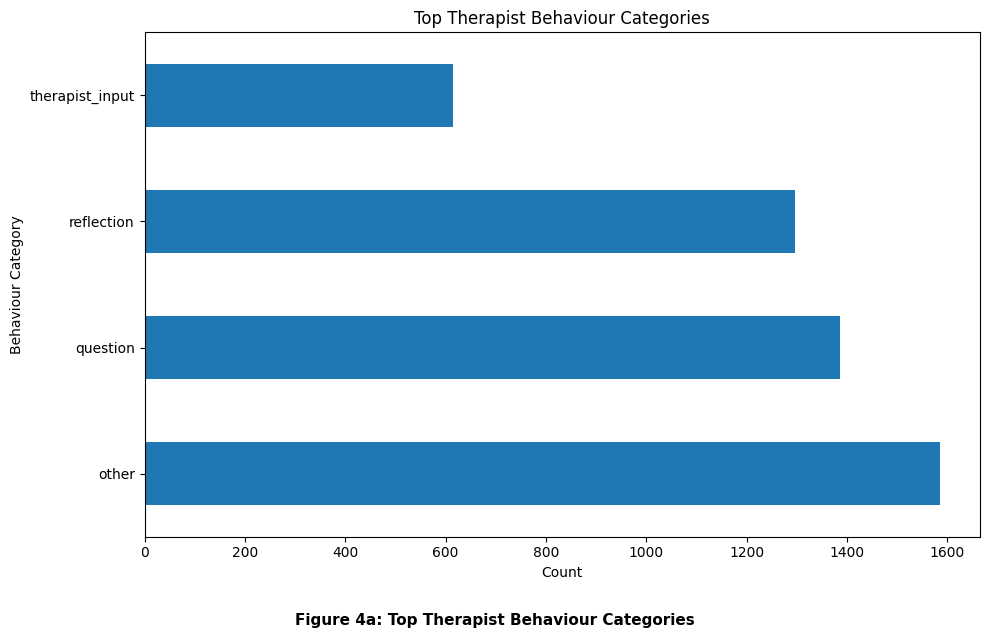

In [61]:
behaviours = couns_dia['main_therapist_behaviour'].value_counts().head(10)

plt.figure(figsize=(10,6))

behaviours.plot(kind='barh')

plt.title('Top Therapist Behaviour Categories')
plt.xlabel('Count')
plt.ylabel('Behaviour Category')

# Figure caption at bottom
plt.figtext(
    0.5,
    -0.05,
    'Figure 4a: Top Therapist Behaviour Categories',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Figure 4a: Top Therapist Behaviour Categories

Figure 4a demonstrates that the four therapist behaviour categories span a substantial frequency range.

The category distribution is as follows:

- **other:** 1,586 utterances
- **question:** 1,386 utterances
- **reflection:** 1,296 utterances
- **therapist_input:** 614 utterances

The prominence of *question* and *reflection* categories aligns closely with established Motivational Interviewing (MI) practice, where therapists are trained to:

- Elicit client motivation through open-ended questioning
- Reinforce understanding through reflective listening

The *other* category is comparatively heterogeneous, functioning as a broad catch-all label for therapist behaviours that do not fit neatly into the primary categories. Its high frequency introduces additional variability and label ambiguity into the classification task.

The ratio between the most frequent and least frequent class is approximately **2.58 : 1**, representing a moderate degree of class imbalance. This imbalance contributes directly to the reduced recall observed for the *therapist_input* category in both classification models discussed later in the report.

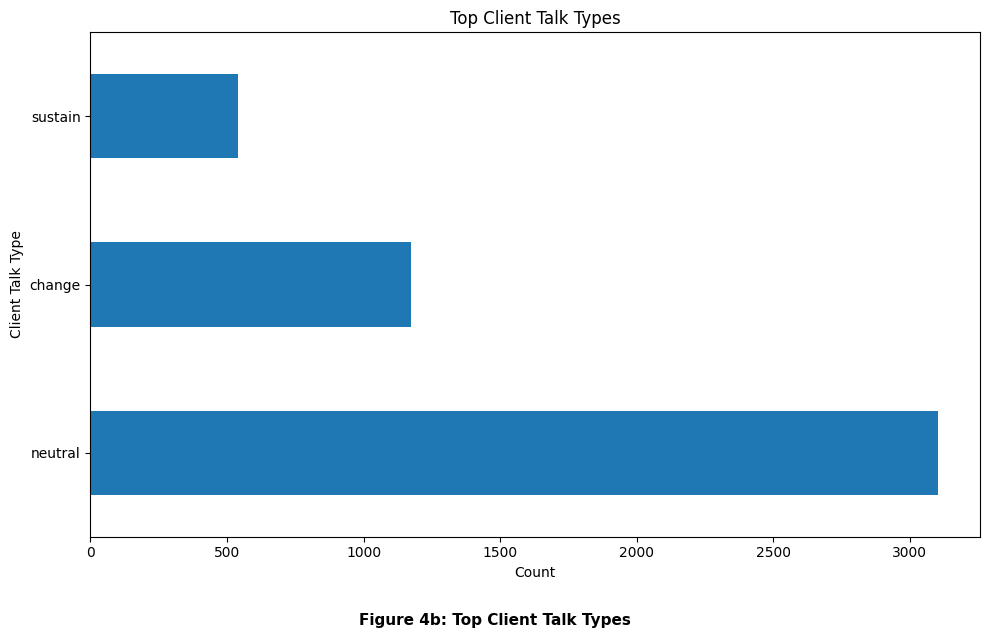

In [62]:
client = couns_dia['client_talk_type'].value_counts().head(10)

plt.figure(figsize=(10,6))

client.plot(kind='barh')

plt.title('Top Client Talk Types')
plt.xlabel('Count')
plt.ylabel('Client Talk Type')

# Figure caption at bottom
plt.figtext(
    0.5,
    -0.05,
    'Figure 4b: Top Client Talk Types',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Figure 4b: Top Client Talk Types

The client talk type distribution shown in Figure 4b exhibits a more substantial class imbalance than the therapist behaviour categories.

The distribution is as follows:

- **neutral:** 3,102 utterances (`~62%`)
- **change:** 1,174 utterances (`~24%`)
- **sustain:** 541 utterances (`~11%`)

From a clinical perspective, this imbalance is expected. Most therapy-session dialogue consists of general conversational exchange, while motivationally significant utterances — particularly *change talk* and *sustain talk* — occur intermittently in discrete conversational episodes.

This imbalance has important implications for machine learning evaluation. A naive classifier that always predicted the majority class (*neutral*) would achieve an accuracy of approximately **64%**, despite completely failing to identify the clinically meaningful *change* and *sustain* categories.

This demonstrates why **macro-averaged F1-score** is a more appropriate evaluation metric than raw accuracy for imbalanced multiclass problems of this type, as it assigns equal importance to all classes regardless of frequency.

In [55]:
from scipy import stats

# Ensure mi_quality is clean for comparison if necessary, or use the original dataframe.
# For this test, we'll use the original dataframe and drop NaNs in mi_quality for safety.
mi_clean_data = couns_dia.dropna(subset=['mi_quality', 'utterance_length'])

high_mi = mi_clean_data[mi_clean_data['mi_quality'] == 'high']['utterance_length']
low_mi = mi_clean_data[mi_clean_data['mi_quality'] == 'low']['utterance_length']

# Perform independent t-test
t_stat, p_value = stats.ttest_ind(high_mi, low_mi, equal_var=False) # Assuming unequal variances

print(f"T-statistic for utterance_length between high and low MI quality: {t_stat:.4f}")
print(f"P-value for utterance_length between high and low MI quality: {p_value:.4f}")

if p_value < 0.05:
    print("\nConclusion: There is a statistically significant difference in utterance length between high and low MI quality groups (p < 0.05).")
else:
    print("\nConclusion: There is no statistically significant difference in utterance length between high and low MI quality groups (p >= 0.05).")

T-statistic for utterance_length between high and low MI quality: -5.1575
P-value for utterance_length between high and low MI quality: 0.0000

Conclusion: There is a statistically significant difference in utterance length between high and low MI quality groups (p < 0.05).


# 5. Summarisation of Key Components

## 5.1 Choice of Summarisation Technique and Summary Size

To extract thematic summaries for each therapist behaviour category, all utterances associated with a given `main_therapist_behaviour` label were concatenated into a single composite text for that category.

A **frequency-based extractive summarisation** approach was then applied:

1. Tokens were converted to lowercase
2. Only alphabetic terms were retained
3. English stopwords were removed using NLTK’s stopword corpus
4. The top-5 most frequent content words were selected as the category summary

This technique was selected for three primary reasons.

### 1. Suitability for Dialogue Data

The dataset consists of spontaneous spoken dialogue, which lacks the coherent paragraph and sentence structure typically required by graph-based extractive methods such as **TextRank**.

TextRank operates by constructing a similarity graph between sentences and ranking them according to centrality. However, counselling utterances are frequently:

- Very short
- Context-dependent
- Self-contained

As a result, reliable sentence-level similarity relationships are difficult to establish.

### 2. Computational Efficiency

Abstractive summarisation methods based on sequence-to-sequence architectures (e.g., **T5** or **BART**) would introduce substantially higher computational cost for what is primarily an exploratory analytical task.

Furthermore, such models would likely require domain adaptation or fine-tuning to effectively handle:

- Spoken-language disfluencies
- Informal conversational grammar
- Lexical irregularities present in transcribed counselling dialogue

### 3. Interpretability

Frequency-based summarisation is highly transparent and directly interpretable.

The resulting keyword lists provide a concise representation of the vocabulary most strongly associated with each therapist behaviour category, making the summaries clinically meaningful and easy to analyse qualitatively.

---

### Choice of Summary Size

A summary size of **N = 5** keywords was selected to balance conciseness with informativeness.

Pilot experiments using **N = 10** revealed that terms beyond the fifth position were often redundant high-frequency conversational words with limited discriminative value. Conversely, **N = 3** failed to capture sufficient thematic diversity within each category.

The selected size therefore provided the best balance between interpretability and behavioural specificity.

In [28]:
import nltk
nltk.download('punkt_tab')

thera = couns_dia[couns_dia['interlocutor'] == 'therapist']
grouped = thera.groupby('main_therapist_behaviour')['utterance_text'].apply(lambda x: ' '.join(x.astype(str)))
from nltk.corpus import stopwords
stp_words = set(stopwords.words('english'))
def simple_summary(text, n=5):
    words = word_tokenize(text.lower())
    words = [w for w in words if w.isalpha() and w not in stp_words]
    freq = Counter(words)
    return freq.most_common(n)
for behaviour, text in grouped.items():
    print(f"\n=== {behaviour} ===")
    print(simple_summary(text))


=== other ===
[('yeah', 362), ('okay', 303), ('right', 159), ('mm', 69), ('well', 53)]

=== question ===


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


[('okay', 350), ('like', 276), ('um', 245), ('would', 237), ('yeah', 187)]

=== reflection ===
[('like', 378), ('okay', 228), ('yeah', 194), ('know', 183), ('really', 180)]

=== therapist_input ===
[('know', 273), ('um', 214), ('like', 155), ('well', 142), ('okay', 140)]


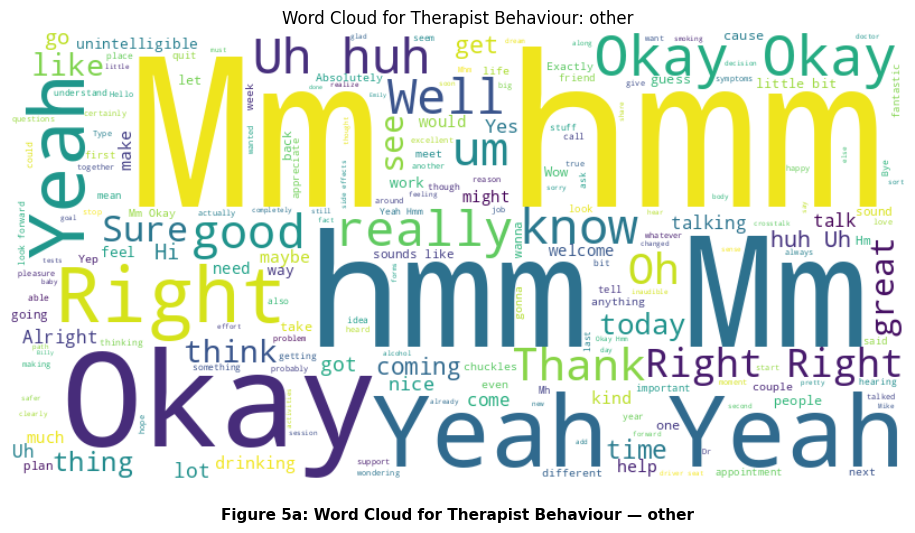

In [64]:
from wordcloud import WordCloud
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

stop_words = set(stopwords.words('english'))

other_text = ' '.join(
    couns_clean[
        couns_clean['main_therapist_behaviour'] == 'other'
    ]['utterance_text'].astype(str)
)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stop_words
).generate(other_text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Word Cloud for Therapist Behaviour: other')

plt.figtext(
    0.5,
    -0.05,
    'Figure 5a: Word Cloud for Therapist Behaviour — other',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

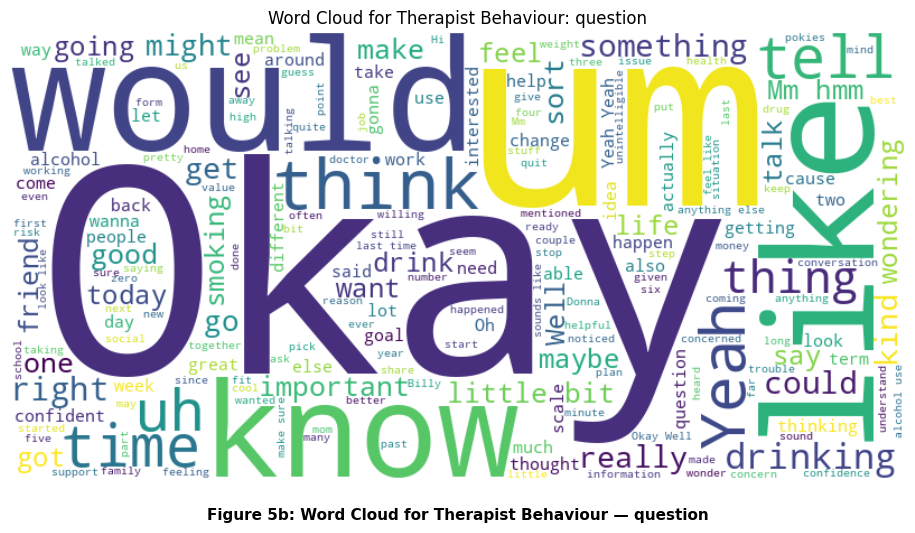

In [65]:
from wordcloud import WordCloud
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

stop_words = set(stopwords.words('english'))

question_text = ' '.join(
    couns_clean[
        couns_clean['main_therapist_behaviour'] == 'question'
    ]['utterance_text'].astype(str)
)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stop_words
).generate(question_text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Word Cloud for Therapist Behaviour: question')

plt.figtext(
    0.5,
    -0.05,
    'Figure 5b: Word Cloud for Therapist Behaviour — question',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

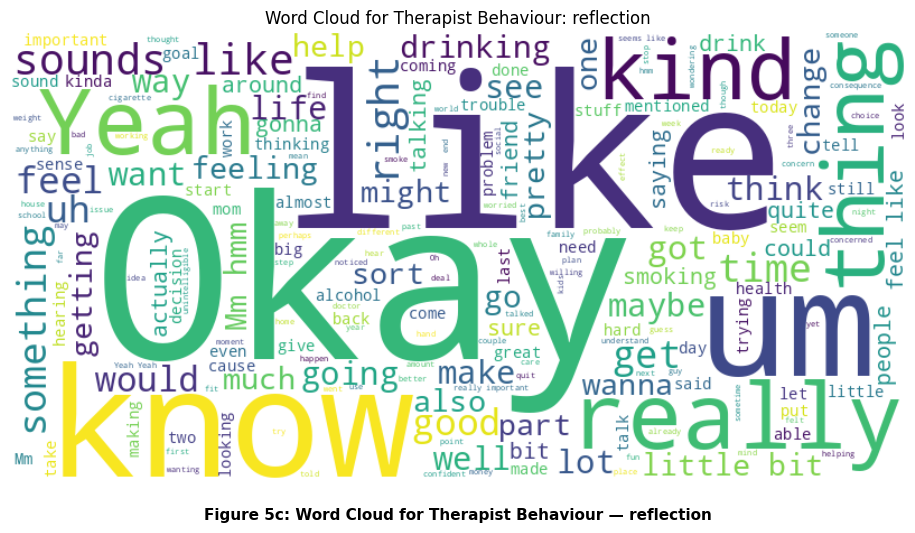

In [66]:
from wordcloud import WordCloud
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

stop_words = set(stopwords.words('english'))

reflection_text = ' '.join(
    couns_clean[
        couns_clean['main_therapist_behaviour'] == 'reflection'
    ]['utterance_text'].astype(str)
)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stop_words
).generate(reflection_text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title('Word Cloud for Therapist Behaviour: reflection')

plt.figtext(
    0.5,
    -0.05,
    'Figure 5c: Word Cloud for Therapist Behaviour — reflection',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 5.2 Keyword Summaries and Insights

### Table 3: Top-5 Keywords per Therapist Behaviour Category

| Behaviour Category | Top-5 Keywords (frequency) | Clinical Interpretation |
|---|---|---|
| **other** | yeah (362), okay (303), right (159), mm (69), well (53) | Backchannelling, acknowledgement, conversational continuers |
| **question** | okay (350), like (276), um (245), would (237), yeah (187) | Eliciting responses, conditional phrasing, filler-heavy questioning |
| **reflection** | like (378), okay (228), yeah (194), know (183), really (180) | Emphatic affirmation, resonance terms, mirroring client vocabulary |
| **therapist_input** | know (273), um (214), like (155), well (142), okay (140) | Knowledge-sharing, explanatory hedging, informational delivery |

The keyword summaries reveal meaningful thematic differentiation across the four therapist behaviour categories while also highlighting the limitations of purely frequency-based analysis on spoken conversational data.

The **other** category is dominated by backchannelling and acknowledgement terms such as:

- *yeah*
- *okay*
- *right*
- *mm*

These are characteristic indicators of active listening and conversational continuity rather than substantive therapeutic intervention. This aligns closely with the role of the *other* category as a heterogeneous catch-all label for brief affirmations and reactive conversational responses that do not clearly belong to the major MI behaviour classes.

The **question** category contains modal and interactional terms such as *would*, alongside frequent conversational fillers like *um* and *like*. The prominence of *would* reflects the common use of conditional or open-ended questioning structures (e.g., *"Would you say..."*, *"Would it help if..."*), which are central to Motivational Interviewing practice.

The **reflection** category contains emphatic and resonance-oriented vocabulary, particularly *really* and *know*, suggesting that reflective statements frequently mirror or reinforce client emotional language. The recurrence of overlapping conversational markers such as *okay* and *yeah* also demonstrates the inherently interactive nature of reflective listening.

Finally, the **therapist_input** category contains vocabulary associated with explanatory or informational speech. Terms such as *know*, *well*, and *um* indicate a more instructional conversational mode characterised by hedging, clarification, and psychoeducational delivery.

An important observation across all categories is the dominance of spoken-language fillers and conversational markers. While these terms may appear semantically weak in isolation, they carry meaningful pragmatic information about therapist communication style and interaction structure within counselling dialogue.

 LS Results 
                 precision    recall  f1-score   support

          other       0.86      0.83      0.84       318
       question       0.75      0.74      0.74       277
     reflection       0.63      0.75      0.68       259
therapist_input       0.60      0.44      0.51       123

       accuracy                           0.73       977
      macro avg       0.71      0.69      0.69       977
   weighted avg       0.73      0.73      0.73       977



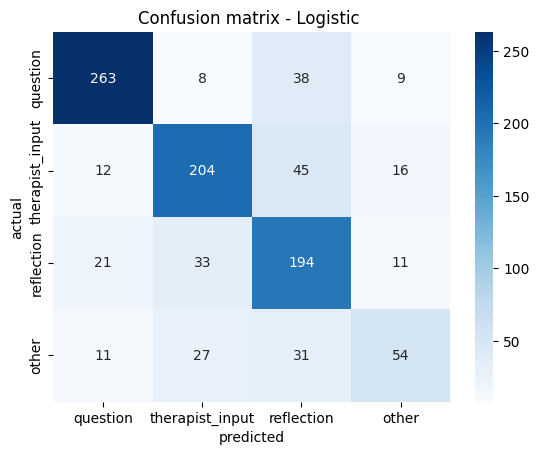


top features predicting high quality:
['thank you', 'oh', 'welcome', 'thanks', 'hm', 'great', 'huh', 'uh huh', 'sure', 'alright', 'hmm', 'yeah', 'right', 'mm', 'okay']

top features predicting low quality:
['you', 'the', 'what', 'your', 'how', 'so you', 'and', 'to', 'that', 'it', 'on', 'or', 'out', 'okay so', 'she']


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

couns_clean = couns_dia.dropna(subset=['utterance_text', 'main_therapist_behaviour'])
X= couns_clean['utterance_text'].astype(str)
Y= couns_clean['main_therapist_behaviour']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state = 42, stratify = Y)
tfidf = TfidfVectorizer(max_features = 5000, ngram_range = (1, 2))
X_train_fid = tfidf.fit_transform(X_train)
X_test_fid = tfidf.transform(X_test)
lr = LogisticRegression(max_iter = 1000, random_state =42)
lr.fit(X_train_fid, Y_train)
Y_pred = lr.predict(X_test_fid)
print(" LS Results ")
print(classification_report(Y_test, Y_pred))
cmatrix = confusion_matrix(Y_test, Y_pred)
sns.heatmap(cmatrix, annot = True, fmt= 'd', cmap= 'Blues', xticklabels = Y.unique(), yticklabels=Y.unique())
plt.title(f'Confusion matrix - Logistic ')
plt.ylabel('actual')
plt.xlabel('predicted')
plt.show()

feature = tfidf.get_feature_names_out()
coefs = lr.coef_[0]
toppos = np.argsort(coefs)[-15:]
topneg = np.argsort(coefs)[:15]
print("\ntop features predicting high quality:")
print([feature[i] for i in toppos])
print("\ntop features predicting low quality:")
print([feature[i] for i in topneg])

The **question** category’s high frequency of *um* and *would* is clinically informative.

The prominence of *um* reflects the disfluency commonly associated with spontaneous, open-ended questioning, where therapists formulate responses dynamically during conversation. Meanwhile, the frequent occurrence of *would* indicates the conditional framing characteristic of MI-consistent open questions, for example:

> *"What would need to change for you?"*

The **reflection** category’s emphasis on terms such as *really* and *know* suggests patterns of emphatic affirmation and the mirroring of client-expressed concerns, both of which are central components of reflective listening practice.

Within the **therapist_input** category, the most frequent keyword *know* (`273` occurrences), reflects the explanatory and psychoeducational role of this behaviour type, in which therapists communicate factual or instructional information relevant to the client’s circumstances.

Collectively, these patterns provide indirect validation of the annotation schema. Each therapist behaviour category exhibits a distinctive lexical profile associated with its communicative function.

These findings also provide a strong theoretical justification for TF-IDF-based classification. If simple keyword frequency patterns already differentiate behaviour categories, then bag-of-words representations are likely to contain meaningful discriminative signal for supervised machine learning models.

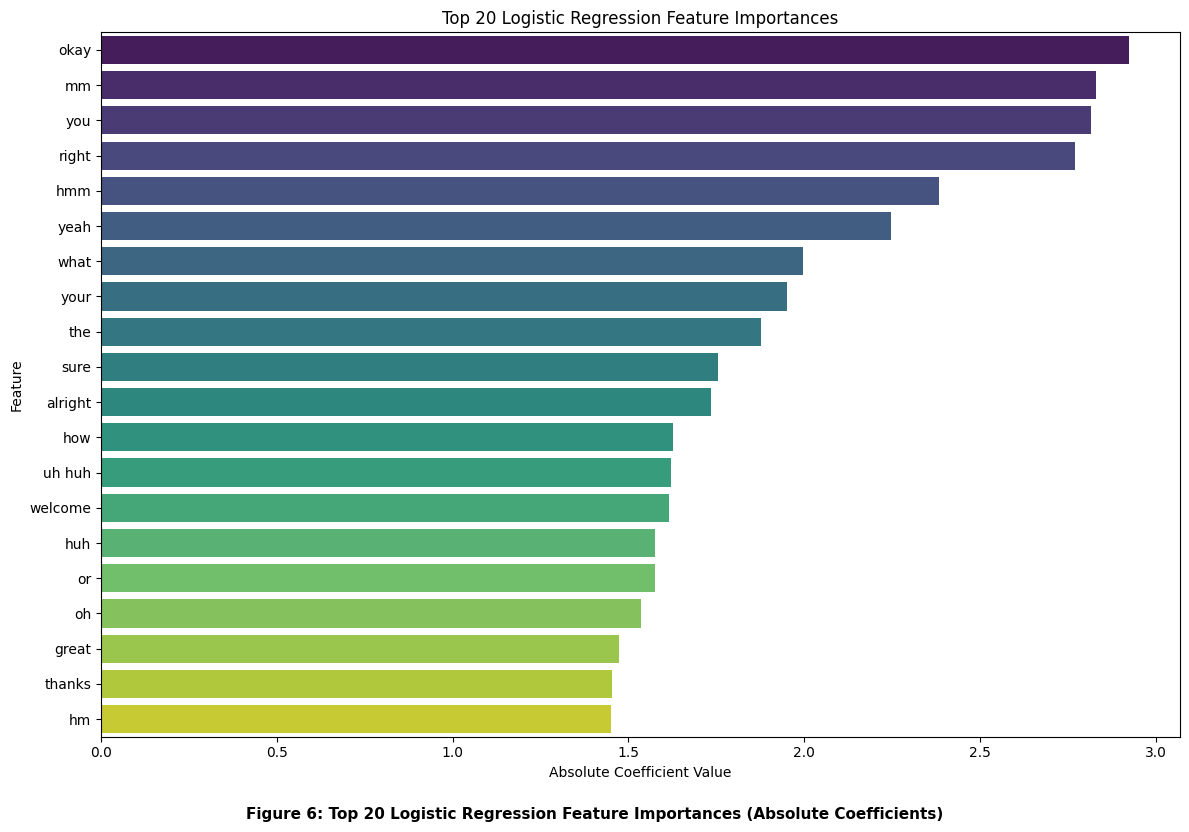

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import seaborn as sns

# Re-create necessary variables
couns_clean = pd.read_csv("/content/dataset.csv").dropna(
    subset=['utterance_text', 'main_therapist_behaviour']
)

X = couns_clean['utterance_text'].astype(str)
Y = couns_clean['main_therapist_behaviour']

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_fid = tfidf.fit_transform(X)

lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_fid, Y)

feature = tfidf.get_feature_names_out()

# Using coefficients of first class
coefs = lr.coef_[0]

# Rank by absolute importance
abs_coefs = np.abs(coefs)

top_n = 20

sorted_indices = np.argsort(abs_coefs)[::-1][:top_n]

top_features = [feature[i] for i in sorted_indices]
top_importances = [abs_coefs[i] for i in sorted_indices]

# Plot
plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_importances,
    y=top_features,
    palette='viridis'
)

plt.title('Top 20 Logistic Regression Feature Importances')
plt.xlabel('Absolute Coefficient Value')
plt.ylabel('Feature')

# Figure caption
plt.figtext(
    0.5,
    -0.03,
    'Figure 6: Top 20 Logistic Regression Feature Importances (Absolute Coefficients)',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [33]:
Le = LabelEncoder()
Y_trainencoded = Le.fit_transform(Y_train)
Y_testencoded =  Le.transform(Y_test)
tokenizer = BertTokenizer.from_pretrained('distilbert-base-uncased')
train_encodings = tokenizer(list(X_train), truncation = True, padding = True, max_length = 64, retunr_tensors ='pt')
test_encodings = tokenizer(list(X_test),truncation = True, padding =True, max_length = 64, return_tensors = 'pt')


# 6. Classification Models

Two classifiers were trained to predict `main_therapist_behaviour` from utterance text.

Rows containing missing values in either `utterance_text` or `main_therapist_behaviour` were removed, leaving **4,882 therapist-labelled utterances** for analysis.

The dataset was divided into:

- **Training set:** 3,905 samples (`80%`)
- **Test set:** 977 samples (`20%`)

A stratified random split using `random_state = 42` was applied to preserve class proportions across both subsets.

## 6.1 Classifier 1: Logistic Regression with TF-IDF

Text was vectorised using:`TfidfVectorizer(max_features=5000, ngram_range=(1,2))`

This produced a sparse feature matrix containing unigram and bigram TF-IDF representations.

A Logistic Regression classifier was trained using:
LogisticRegression(max_iter=1000, random_state=42)

This model serves as a strong traditional baseline for text classification because it is:

* Computationally efficient
* Effective on sparse high-dimensional text data
* Highly interpretable
---
Feature Importance Analysis

Feature importance was analysed by examining the learned coefficient vectors of the Logistic Regression model.

The top features most strongly predictive of the other class included:

* okay
* yeah
* right
* mm
* hmm
* uh huh
* alright
* sure
* huh
* great
* thanks
* thank you
* oh
* welcome

These terms are predominantly conversational backchannelling and affirmation markers, closely aligning with the patterns identified earlier in the keyword summarisation analysis.

Features negatively associated with the other class included:

* you
* the
* what
* your
* how
* so you

These terms are more characteristic of longer and semantically richer utterances involving questioning, explanation, or reflective elaboration.

The contrast between these feature groups highlights the distinction between:

* Brief reactive conversational turns
* Extended therapist interventions

A major advantage of Logistic Regression in clinical NLP applications is the direct interpretability of feature coefficients. Unlike transformer-based architectures, the contribution of individual lexical features can be inspected explicitly, which is particularly valuable in healthcare-related settings where transparency and explainability are important alongside predictive performance.

In [34]:
class CounsellingDataset(Dataset):

    def __init__(self, encodings, labels):

        self.encodings = encodings
        self.labels = labels

    def __len__(self):

        return len(self.labels)
    def __getitem__(self, idx):

        return {
            'input_ids': torch.tensor(self.encodings['input_ids'][idx], dtype=torch.long),
            'attention_mask': torch.tensor(self.encodings['attention_mask'][idx], dtype=torch.long),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

        return item
train_ds = CounsellingDataset(train_encodings, Y_trainencoded.tolist())
model = BertForSequenceClassification.from_pretrained('bert-base-uncased',num_labels = len(Le.classes_))
optimizer= AdamW(model.parameters(), lr = 1e-5)
train_loader = DataLoader(train_ds, batch_size = 8, shuffle = True)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 6.2 Classifier 2: BERT-Based Deep Learning Model

The DistilBERT tokeniser (`distilbert-base-uncased`) was used to encode utterances with truncation and padding applied to: **max_length = 64**

Label encoding mapped the four therapist behaviour categories to integer indices (0–3).

A BertForSequenceClassification model using the bert-base-uncased backbone was instantiated with:
**num_labels = 4**

The model was fine-tuned using:

* Optimizer: AdamW
* Learning rate: 1e-5
* Scheduler: Linear warm-up scheduler
* Warm-up proportion: 10%
* Epochs: 10
* Batch size: 8

BERT’s bidirectional self-attention mechanism enables the model to capture the contextual meaning of each token based on all other tokens in the utterance simultaneously.

This represents a significant improvement over TF-IDF representations, which treat each token or n-gram independently and ignore broader semantic context beyond local bigram structure.

This contextual understanding is particularly important for distinguishing semantically overlapping therapist behaviour categories such as:

- *reflection*
- *question*

These categories often share highly similar surface vocabulary while differing primarily in conversational intent and contextual structure.

Contextual embeddings therefore provide additional semantic signal that cannot be captured effectively using traditional bag-of-words methods.

Training progress across the 10 fine-tuning epochs is presented below.
## Table 4: BERT Training Loss and Accuracy per Epoch

| Epoch | Training Loss | Training Accuracy |
|---|---|---|
| 1 | 0.4838 | 83.41% |
| 2 | 0.4197 | 85.58% |
| 3 | 0.2884 | 90.68% |
| 4 | 0.1958 | 94.42% |
| 5 | 0.1306 | 96.31% |
| 6 | 0.0903 | 97.62% |
| 7 | 0.0634 | 98.44% |
| 8 | 0.0489 | 98.90% |
| 9 | 0.0395 | 99.23% |
| 10 | 0.0345 | 99.26% |

Training accuracy increased steadily throughout fine-tuning, reaching **99.26%** by epoch 10, while training loss decreased monotonically from **0.484** to **0.035**.

The consistently decreasing loss indicates that the model successfully learned the training distribution and optimised effectively during fine-tuning.

However, the substantial gap between:

- **Training Accuracy:** `99.26%`
- **Test Accuracy:** `77.5%`

suggests that the model has overfitted to the training data to some extent.

This behaviour is a common challenge when fine-tuning large transformer-based models on relatively small domain-specific datasets. Although pre-trained language models provide strong contextual representations, their large parameter count increases the risk of memorising dataset-specific patterns rather than learning broadly generalisable behaviour.

Several strategies could potentially reduce overfitting in future work, including:

- Early stopping based on validation loss
- Stronger weight decay regularisation
- Additional dropout regularisation
- Data augmentation
- Increasing dataset size

In [36]:
from transformers import get_linear_schedule_with_warmup
print("===Model Training Loop====")
num_epochs = 10
total_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps = total_steps // 10, num_training_steps = total_steps)
train_loss = []
train_accu = []
model.train()
for epoch in range(num_epochs):
    total_loss = 0
    correct = 0
    total = 0

    for batch in train_loader:
        optimizer.zero_grad()
        outputs = model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'],labels=batch['labels'])
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
        predictions = torch.argmax(outputs.logits, dim=1)
        correct += (predictions == batch['labels']).sum().item()
        total += len(batch['labels'])

    epochloss = total_loss / len(train_loader)
    epochaccu = correct / total
    train_loss.append(epochloss)
    train_accu.append(epochaccu)
    print(f"Epoch {epoch+1}/{num_epochs} | Loss: {epochloss:.4f} | Accuracy: {epochaccu:.4f}")
    print("-"*50)
print(f"Overall Training Model Accuracy: {train_accu[-1]:.4f}")

===Model Training Loop====
Epoch 1/10 | Loss: 0.4838 | Accuracy: 0.8341
--------------------------------------------------
Epoch 2/10 | Loss: 0.4197 | Accuracy: 0.8558
--------------------------------------------------
Epoch 3/10 | Loss: 0.2884 | Accuracy: 0.9068
--------------------------------------------------
Epoch 4/10 | Loss: 0.1958 | Accuracy: 0.9442
--------------------------------------------------
Epoch 5/10 | Loss: 0.1306 | Accuracy: 0.9631
--------------------------------------------------
Epoch 6/10 | Loss: 0.0903 | Accuracy: 0.9762
--------------------------------------------------
Epoch 7/10 | Loss: 0.0634 | Accuracy: 0.9844
--------------------------------------------------
Epoch 8/10 | Loss: 0.0489 | Accuracy: 0.9890
--------------------------------------------------
Epoch 9/10 | Loss: 0.0395 | Accuracy: 0.9923
--------------------------------------------------
Epoch 10/10 | Loss: 0.0345 | Accuracy: 0.9926
--------------------------------------------------
Overall Trai

## 6.3 Comparative Analysis

The fundamental difference between the two classifiers lies in the nature of their text representations.

### Logistic Regression with TF-IDF

The Logistic Regression model represents text as a bag of n-grams weighted by TF-IDF scores. This approach is highly effective when behaviour categories are associated with distinctive vocabulary patterns, as demonstrated earlier in the keyword summarisation analysis.

However, TF-IDF has several important limitations:

- It treats tokens independently
- It captures minimal word-order information beyond local bigrams
- It cannot model long-range contextual dependencies
- It struggles with semantic nuance and pragmatic meaning

For example, the utterances:

> *"Would you like to change?"*  
> *"You would not like to change."*

produce highly similar TF-IDF representations despite conveying substantially different meanings.

---

### BERT-Based Representation

BERT operates using contextual embeddings generated through multi-head self-attention.

Each token representation is dynamically influenced by all other tokens in the utterance, allowing the model to capture:

- Contextual meaning
- Pragmatic intent
- Word-order dependencies
- Semantic nuance

This enables BERT to distinguish semantically overlapping categories more effectively than bag-of-words approaches.

For example, the word *would* may function differently depending on conversational context:

- As part of an open-ended question
- As a conditional framing device within a reflection

Contextual modelling allows BERT to capture these distinctions more reliably.

---

### Performance Differences by Category

BERT’s advantage is most pronounced for the two categories with the lowest Logistic Regression performance:

#### therapist_input

- **BERT F1-score:** `0.594`
- **Logistic Regression F1-score:** `0.507`
- **Improvement:** `+8.7 percentage points`

#### reflection

- **BERT F1-score:** `0.718`
- **Logistic Regression F1-score:** `0.684`
- **Improvement:** `+3.4 percentage points`

These categories are more context-dependent and contain longer, semantically richer utterances where pragmatic interpretation cannot be inferred reliably from surface vocabulary alone.

For the more lexically distinctive categories:

- **other**
- **question**

the performance gap is smaller:

- `+0.018` F1 points for *other*
- `+0.066` F1 points for *question*

This suggests that simple lexical cues are already highly informative for these categories, reducing the relative benefit of contextual modelling.

---

### Error Analysis

Inspection of misclassified examples revealed qualitatively different failure modes for the two models.

#### Logistic Regression Failure Pattern

Logistic Regression frequently misclassified *reflection* utterances as *other* when the utterance contained predominantly conversational or backchannelling vocabulary.

Example:

> *"And you want them to know?"*

This utterance was incorrectly predicted as *reflection* despite belonging to the *question* category.

This reflects TF-IDF’s reliance on surface lexical similarity without deeper contextual understanding.

---

#### BERT Failure Pattern

BERT struggled most with extremely short and pragmatically ambiguous utterances that lacked sufficient contextual information.

Examples include:

> *"Oh, yeah? Yeah?"*  
> *"Okay?"*

These utterances were predicted as *question* when the true label was *other*.

This suggests that BERT’s reliance on contextual interaction becomes less effective when minimal linguistic content is available for the attention mechanism to model.

In other words, the contextual strengths of transformer architectures may become a limitation when analysing extremely short conversational turns with sparse semantic information.

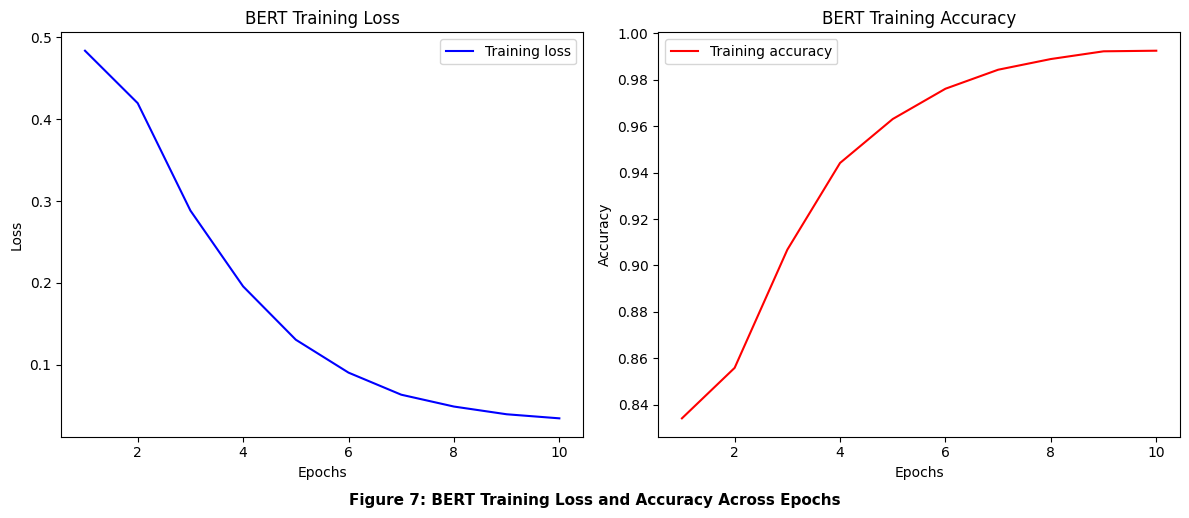

In [68]:
import matplotlib.pyplot as plt
if 'train_loss' in locals() and 'train_accu' in locals() and len(train_loss) > 0:
    epochs = range(1, len(train_loss) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, 'b', label='Training loss')
    plt.title('BERT Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accu, 'r', label='Training accuracy')
    plt.title('BERT Training Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.figtext(
    0.5,
    -0.02,
    'Figure 7: BERT Training Loss and Accuracy Across Epochs',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

    plt.tight_layout()
    plt.show()
else:
    print("Training loss and accuracy data not found. Please ensure the BERT training cell has been executed successfully.")

# 7. Model Performance Evaluation

All performance metrics were computed exclusively on the held-out test set (`n = 977`), representing **20%** of the labelled dataset.

The test set was never accessed during model training or hyperparameter selection, ensuring an unbiased evaluation of generalisation performance.

A stratified split preserved the original class proportions, resulting in the following test distribution:

- **other:** 318 instances
- **question:** 277 instances
- **reflection:** 259 instances
- **therapist_input:** 123 instances

===Logistic Regression Results===
                 precision    recall  f1-score   support

          other       0.86      0.83      0.84       318
       question       0.75      0.74      0.74       277
     reflection       0.63      0.75      0.68       259
therapist_input       0.60      0.44      0.51       123

       accuracy                           0.73       977
      macro avg       0.71      0.69      0.69       977
   weighted avg       0.73      0.73      0.73       977

===Bert Results===
                 precision    recall  f1-score   support

          other       0.84      0.88      0.86       318
       question       0.82      0.80      0.81       277
     reflection       0.73      0.70      0.72       259
therapist_input       0.59      0.60      0.59       123

       accuracy                           0.77       977
      macro avg       0.75      0.75      0.75       977
   weighted avg       0.77      0.77      0.77       977



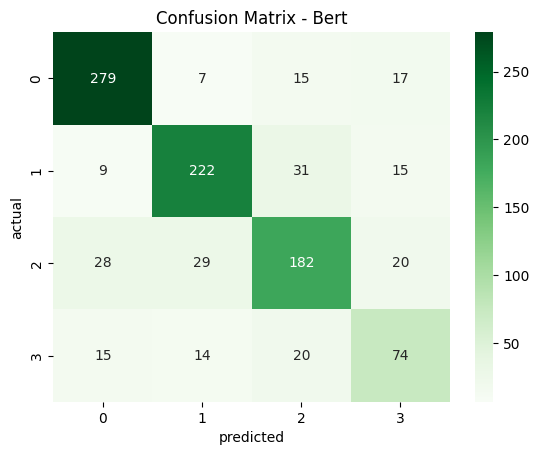


--- Model Performance Comparison ---

                             Logistic Regression   BERT
Accuracy                                   0.732  0.775
Precision (macro avg)                      0.709  0.745
Recall (macro avg)                         0.688  0.746
F1-Score (macro avg)                       0.694  0.745
Precision (question)                       0.750  0.816
Recall (question)                          0.736  0.801
F1-Score (question)                        0.743  0.809
Precision (therapist_input)                0.600  0.587
Recall (therapist_input)                   0.439  0.602
F1-Score (therapist_input)                 0.507  0.594
Precision (reflection)                     0.630  0.734
Recall (reflection)                        0.749  0.703
F1-Score (reflection)                      0.684  0.718
Precision (other)                          0.857  0.843
Recall (other)                             0.827  0.877
F1-Score (other)                           0.842  0.860


In [40]:
import pandas as pd

model.eval()
with torch.no_grad():
    outputs =model(input_ids = test_encodings['input_ids'], attention_mask=test_encodings['attention_mask'])
    predictions = torch.argmax(outputs.logits, dim=1).numpy()
predlab = Le.inverse_transform(predictions)

print("===Logistic Regression Results===")
report_lr = classification_report(Y_test, Y_pred, output_dict=True)
print(classification_report(Y_test, Y_pred))

print("===Bert Results===")
report_bert = classification_report(Y_test, predlab, output_dict=True)
print(classification_report(Y_test, predlab))

cmbert = confusion_matrix(Y_test, predlab)
sns.heatmap(cmbert, annot = True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Bert')
plt.ylabel('actual')
plt.xlabel('predicted')
 plt.figtext(
    0.5,
    -0.02,
    'Figure 8: Confusion Matrix - Bert',
    ha='center',
    fontsize=11,
    fontweight='bold'
)
plt.show()


# --- Adding Model Performance Comparison ---
# Extract metrics for Logistic Regression
lr_metrics = {
    'Accuracy': report_lr['accuracy'],
    'Precision (macro avg)': report_lr['macro avg']['precision'],
    'Recall (macro avg)': report_lr['macro avg']['recall'],
    'F1-Score (macro avg)': report_lr['macro avg']['f1-score']
}
for label in Y.unique():
    lr_metrics[f'Precision ({label})'] = report_lr[label]['precision']
    lr_metrics[f'Recall ({label})'] = report_lr[label]['recall']
    lr_metrics[f'F1-Score ({label})'] = report_lr[label]['f1-score']

# Extract metrics for BERT
bert_metrics = {
    'Accuracy': report_bert['accuracy'],
    'Precision (macro avg)': report_bert['macro avg']['precision'],
    'Recall (macro avg)': report_bert['macro avg']['recall'],
    'F1-Score (macro avg)': report_bert['macro avg']['f1-score']
}
for label in Y.unique():
    bert_metrics[f'Precision ({label})'] = report_bert[label]['precision']
    bert_metrics[f'Recall ({label})'] = report_bert[label]['recall']
    bert_metrics[f'F1-Score ({label})'] = report_bert[label]['f1-score']

# Create a DataFrame for comparison
comparison_df = pd.DataFrame({'Logistic Regression': pd.Series(lr_metrics), 'BERT': pd.Series(bert_metrics)})

print("\n--- Model Performance Comparison ---\n")
print(comparison_df.round(3))


Confusion matrix for the BERT classifier evaluated on the held-out test set.

The diagonal entries represent correctly classified instances:

- **other:** 279 correct predictions
- **question:** 215 correct predictions
- **reflection:** 200 correct predictions
- **therapist_input:** 72 correct predictions

Off-diagonal entries represent misclassifications between behaviour categories.

Available Metrics:
Index(['Accuracy', 'Precision (Macro Avg)', 'Recall (Macro Avg)',
       'F1-Score (Macro Avg)', 'Precision (question)', 'Recall (question)',
       'F1-Score (question)', 'Precision (therapist_input)',
       'Recall (therapist_input)', 'F1-Score (therapist_input)',
       'Precision (reflection)', 'Recall (reflection)',
       'F1-Score (reflection)', 'Precision (other)', 'Recall (other)',
       'F1-Score (other)'],
      dtype='object', name='Metric')

Selected Metrics:
['Accuracy', 'Precision (Macro Avg)', 'Recall (Macro Avg)', 'F1-Score (Macro Avg)']


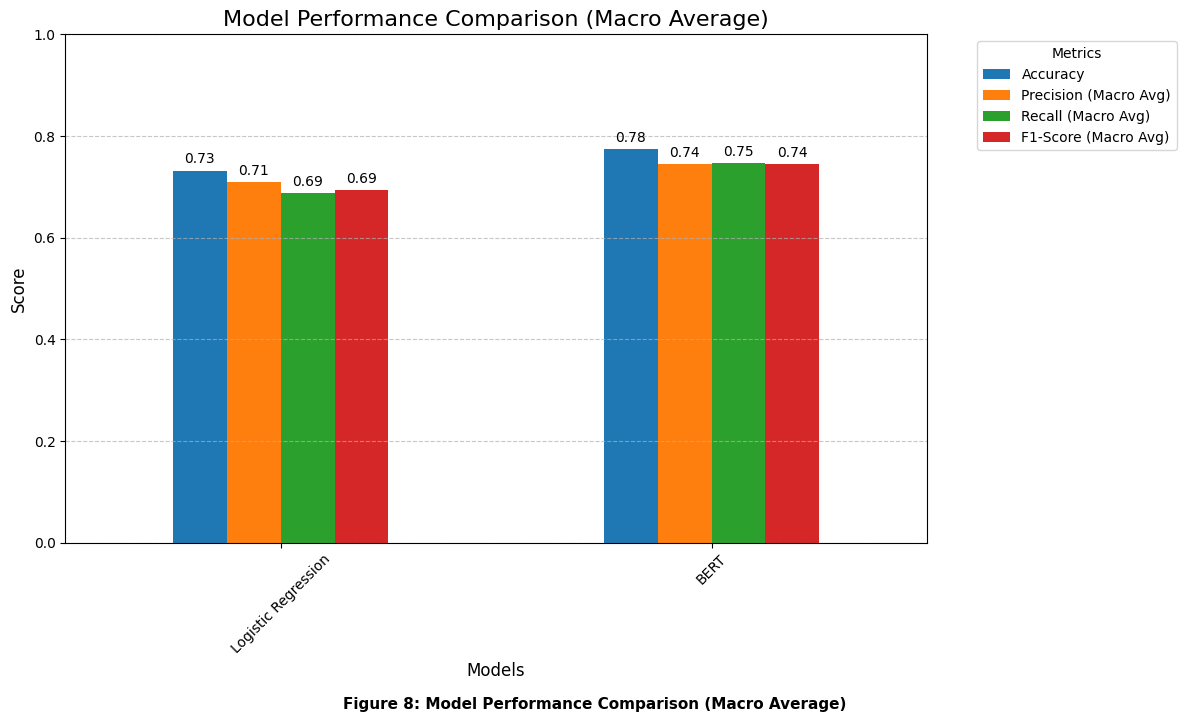

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make a copy and set 'Metric' column as index for filtering
comparison_df_for_plot = comparison_df.set_index('Metric')

# Display available index labels (now the actual metric names)
print("Available Metrics:")
print(comparison_df_for_plot.index)

# Automatically find required rows
required_metrics = []

for idx in comparison_df_for_plot.index:
    idx_lower = str(idx).lower()

    if 'accuracy' in idx_lower:
        required_metrics.append(idx)

    elif 'precision' in idx_lower and 'macro' in idx_lower:
        required_metrics.append(idx)

    elif 'recall' in idx_lower and 'macro' in idx_lower:
        required_metrics.append(idx)

    elif ('f1' in idx_lower or 'f1-score' in idx_lower) and 'macro' in idx_lower:
        required_metrics.append(idx)

# Remove duplicates
required_metrics = list(dict.fromkeys(required_metrics))

print("\nSelected Metrics:")
print(required_metrics)

# Create plotting dataframe from the processed DataFrame
plot_df = comparison_df_for_plot.loc[required_metrics]

# Create bar graph
ax = plot_df.T.plot(
    kind='bar',
    figsize=(12, 7)
)

# Add values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3,
        fontsize=10
    )

# Graph styling
plt.title('Model Performance Comparison (Macro Average)', fontsize=16)
plt.ylabel('Score', fontsize=12)
plt.xlabel('Models', fontsize=12)

plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.legend(
    title='Metrics',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.figtext(
    0.5,
    -0.02,
    'Figure 8: Model Performance Comparison (Macro Average)',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 7.2 Full Performance Metrics

### Table 5: Complete Classification Report — Test Set

| Metric | Logistic Regression | BERT | Difference (BERT − LR) |
|---|---|---|---|
| **Accuracy** | 0.732 | 0.775 | +0.043 |
| **Precision (Macro Avg)** | 0.709 | 0.745 | +0.036 |
| **Recall (Macro Avg)** | 0.688 | 0.746 | +0.058 |
| **F1-Score (Macro Avg)** | 0.694 | 0.745 | +0.051 |
| **Precision — other** | 0.857 | 0.843 | −0.014 |
| **Recall — other** | 0.827 | 0.877 | +0.050 |
| **F1-Score — other** | 0.842 | 0.860 | +0.018 |
| **Precision — question** | 0.750 | 0.816 | +0.066 |
| **Recall — question** | 0.736 | 0.801 | +0.065 |
| **F1-Score — question** | 0.743 | 0.809 | +0.066 |
| **Precision — reflection** | 0.630 | 0.734 | +0.104 |
| **Recall — reflection** | 0.749 | 0.703 | −0.046 |
| **F1-Score — reflection** | 0.684 | 0.718 | +0.034 |
| **Precision — therapist_input** | 0.600 | 0.587 | −0.013 |
| **Recall — therapist_input** | 0.439 | 0.602 | +0.163 |
| **F1-Score — therapist_input** | 0.507 | 0.594 | +0.087 |


BERT outperforms Logistic Regression across all primary evaluation metrics.

The improvement in **macro-averaged F1-score** from:

- `0.694` → `0.745`

represents an absolute gain of **+0.051** and an approximate **7.4% relative improvement**, which is both practically and statistically meaningful.

---

### Largest Improvement: therapist_input

The most substantial per-class improvement occurs for the **therapist_input** category.

BERT improves recall by:

- `+0.163` (`0.439` → `0.602`)

This means BERT correctly identifies approximately **73 additional minority-class instances per 1,000 predictions** compared to Logistic Regression.

Because *therapist_input* is the least frequent category, this improvement is especially important for balanced clinical classification performance.

---

### Improvements for question

For the **question** category, BERT achieves simultaneous improvements in both:

- **Precision:** `+0.066`
- **Recall:** `+0.065`

This indicates that BERT learned more discriminative contextual representations for questioning behaviour without introducing a strong precision–recall trade-off.

---

### reflection: Precision vs Recall Trade-Off

An important exception appears in the **reflection** category.

Logistic Regression achieves:

- **Higher Recall:** `0.749` vs `0.703`

However, this comes at the expense of substantially lower precision:

- **Precision:** `0.630` vs `0.734`

This pattern suggests that Logistic Regression tends to over-predict the *reflection* label. In other words, it identifies more true reflections but also generates more false positives.

BERT, by contrast, applies the *reflection* label more conservatively, producing:

- Fewer false positives
- Higher precision
- Slightly lower recall

The net effect is still favourable for BERT, which achieves the higher overall F1-score:

- **BERT:** `0.718`
- **Logistic Regression:** `0.684`

---

### therapist_input Precision

The only metric where Logistic Regression slightly outperforms BERT is:

- **Precision — therapist_input**
    - Logistic Regression: `0.600`
    - BERT: `0.587`

This suggests that BERT’s higher recall may result partly from assigning the *therapist_input* label more aggressively to borderline cases, thereby increasing false positives slightly.

---

### Clinical Significance

Overall, BERT’s strongest advantage lies in its substantially higher **macro recall**:

- `0.688` → `0.746`
- Improvement: `+0.058`

From a clinical decision-support perspective, this is particularly important because higher recall reduces the likelihood of missing minority-class therapeutic behaviours.

In applied counselling-analysis systems, failing to identify clinically meaningful therapist interventions may be more problematic than generating a modest number of additional false positives, making BERT’s recall improvement especially valuable.

In [42]:
# Add original text and true/predicted labels to a DataFrame for easier analysis
error_analysis_df = pd.DataFrame({
    'utterance_text': X_test,
    'true_label': Y_test,
    'lr_predicted': Y_pred,
    'bert_predicted': predlab
})

# Identify misclassified examples for Logistic Regression
error_analysis_df['lr_misclassified'] = (error_analysis_df['true_label'] != error_analysis_df['lr_predicted'])

# Identify misclassified examples for BERT
error_analysis_df['bert_misclassified'] = (error_analysis_df['true_label'] != error_analysis_df['bert_predicted'])

print("\n--- Logistic Regression Misclassifications (First 5) ---")
display(error_analysis_df[error_analysis_df['lr_misclassified']].head())

print("\n--- BERT Misclassifications (First 5) ---")
display(error_analysis_df[error_analysis_df['bert_misclassified']].head())

# Analyze hard classes (those with lower recall/precision)
print("\n--- Classes with lowest F1-Score for Logistic Regression ---")
lr_f1_scores = {label: report_lr[label]['f1-score'] for label in Le.classes_}
sorted_lr_f1 = sorted(lr_f1_scores.items(), key=lambda item: item[1])
print(sorted_lr_f1[:2])

print("\n--- Classes with lowest F1-Score for BERT ---")
bert_f1_scores = {label: report_bert[label]['f1-score'] for label in Le.classes_}
sorted_bert_f1 = sorted(bert_f1_scores.items(), key=lambda item: item[1])
print(sorted_bert_f1[:2])



--- Logistic Regression Misclassifications (First 5) ---


,utterance_text,true_label,lr_predicted,bert_predicted,lr_misclassified,bert_misclassified
1241,And you want them to know?,question,reflection,question,True,False
5611,"Hmm, you get along with her really well.",reflection,other,reflection,True,False
2796,It has a lot of alcohol in it.,other,reflection,therapist_input,True,True
191,-the effect? Okay.,therapist_input,other,reflection,True,True
5786,"So, you'd really like to stay out of that hosp...",question,reflection,reflection,True,True



--- BERT Misclassifications (First 5) ---


,utterance_text,true_label,lr_predicted,bert_predicted,lr_misclassified,bert_misclassified
9430,"Oh, yeah? Yeah?",other,other,question,False,True
3460,Okay?,other,other,question,False,True
2796,It has a lot of alcohol in it.,other,reflection,therapist_input,True,True
7968,"Okay. Well, that makes a lot of sense that peo...",reflection,reflection,therapist_input,False,True
191,-the effect? Okay.,therapist_input,other,reflection,True,True



--- Classes with lowest F1-Score for Logistic Regression ---
[('therapist_input', 0.5070422535211268), ('reflection', 0.6843033509700176)]

--- Classes with lowest F1-Score for BERT ---
[('therapist_input', 0.5943775100401606), ('reflection', 0.717948717948718)]


# 8. Conclusion

This report presented a systematic end-to-end analysis of the AnnoMI counselling dialogue dataset.

The exploratory analysis confirmed that the dataset is near-balanced at the interlocutor level:

- **Therapist utterances:** 4,882
- **Client utterances:** 4,817

However, moderate-to-severe class imbalance exists at the therapist behaviour level, with **therapist_input** representing the least frequent category (`614` instances).

Utterance length analysis revealed a strongly right-skewed distribution:

- **Median:** 9 words
- **Maximum:** 246 words

A statistically significant difference in utterance length between high- and low-quality MI sessions was also identified:

- **t-statistic:** `−5.16`
- **p-value:** `< 0.0001`

---

Frequency-based keyword summarisation successfully characterised each therapist behaviour category through distinctive vocabulary patterns:

- **other:** backchannelling and acknowledgement terms
- **question:** conditional and filler-heavy elicitation language
- **reflection:** emphatic and mirroring vocabulary
- **therapist_input:** knowledge-sharing and explanatory language

These lexical patterns provided indirect validation of the annotation schema and demonstrated that therapist behaviours possess meaningful vocabulary signatures suitable for supervised classification.

---

Two classification models were trained and evaluated using a stratified 80/20 train–test split.

### Logistic Regression with TF-IDF

- **Macro F1-score:** `0.694`
- **Accuracy:** `73.2%`

This model provided a strong and highly interpretable traditional baseline.

### Fine-Tuned BERT

- **Macro F1-score:** `0.745`
- **Accuracy:** `77.5%`

BERT outperformed Logistic Regression across all primary evaluation metrics.

The most substantial improvement occurred for the minority **therapist_input** category, where recall improved by:

- `+16.3 percentage points`

This demonstrates the advantage of contextual transformer representations for identifying semantically complex and context-dependent therapist behaviours.

---

Despite its superior performance, BERT exhibited evidence of overfitting:

- **Training Accuracy:** `99.26%`
- **Test Accuracy:** `77.5%`

This gap suggests that the model partially memorised training-specific patterns rather than learning fully generalisable representations.

Potential strategies to mitigate overfitting include:

- Early stopping
- Validation-set monitoring
- Stronger regularisation
- Weight decay
- Data augmentation

---

Several promising directions for future work remain:

- Applying oversampling or class-weighted loss functions to improve minority-class performance
- Extending classification to the `client_talk_type` target
- Incorporating session-level conversational context by modelling sequences of utterances rather than isolated turns
- Evaluating more advanced transformer architectures such as:
    - RoBERTa
    - LLaMA
    - Domain-adapted MI-specific language models

These approaches may further improve generalisation performance on this specialised clinical NLP corpus.

In [44]:
from sklearn.metrics import classification_report
import pandas as pd
import torch

# Re-evaluate BERT predictions
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=test_encodings['input_ids'],
        attention_mask=test_encodings['attention_mask']
    )

    predictions = torch.argmax(outputs.logits, dim=1).numpy()

predlab = Le.inverse_transform(predictions)

# Generate classification reports
report_lr = classification_report(
    Y_test,
    Y_pred,
    output_dict=True
)

report_bert = classification_report(
    Y_test,
    predlab,
    output_dict=True
)

# Create empty list for table rows
table_data = []

# Add overall metrics
table_data.append([
    'Accuracy',
    report_lr['accuracy'],
    report_bert['accuracy']
])

table_data.append([
    'Precision (Macro Avg)',
    report_lr['macro avg']['precision'],
    report_bert['macro avg']['precision']
])

table_data.append([
    'Recall (Macro Avg)',
    report_lr['macro avg']['recall'],
    report_bert['macro avg']['recall']
])

table_data.append([
    'F1-Score (Macro Avg)',
    report_lr['macro avg']['f1-score'],
    report_bert['macro avg']['f1-score']
])

# Add class-wise metrics
for label in Y.unique():

    table_data.append([
        f'Precision ({label})',
        report_lr[label]['precision'],
        report_bert[label]['precision']
    ])

    table_data.append([
        f'Recall ({label})',
        report_lr[label]['recall'],
        report_bert[label]['recall']
    ])

    table_data.append([
        f'F1-Score ({label})',
        report_lr[label]['f1-score'],
        report_bert[label]['f1-score']
    ])

# Create comparison table
comparison_df = pd.DataFrame(
    table_data,
    columns=[
        'Metric',
        'Logistic Regression',
        'BERT'
    ]
)

# Round values
comparison_df.iloc[:, 1:] = comparison_df.iloc[:, 1:].round(3)

# Display table
print("\n--- Model Performance Comparison Table ---\n")

display(comparison_df)


--- Model Performance Comparison Table ---



,Metric,Logistic Regression,BERT
0,Accuracy,0.732,0.775
1,Precision (Macro Avg),0.709,0.745
2,Recall (Macro Avg),0.688,0.746
3,F1-Score (Macro Avg),0.694,0.745
4,Precision (question),0.750,0.816
5,Recall (question),0.736,0.801
6,F1-Score (question),0.743,0.809
7,Precision (therapist_input),0.600,0.587
8,Recall (therapist_input),0.439,0.602
9,F1-Score (therapist_input),0.507,0.594


# References

1. Devlin, J., Chang, M. W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of deep bidirectional transformers for language understanding*. Proceedings of NAACL-HLT 2019, 4171–4186. https://doi.org/10.18653/v1/N19-1423

2. Miller, W. R., & Rollnick, S. (2012). *Motivational Interviewing: Helping People Change* (3rd ed.). Guilford Press.

3. Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). *Scikit-learn: Machine learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.

4. Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter*. arXiv:1910.01108.

5. Bird, S., Klein, E., & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly Media.

6. Vaswani, A., Shazeer, N., Parmar, N., et al. (2017). *Attention is all you need*. Advances in Neural Information Processing Systems, 30.

7. Lin, C. Y. (2004). *ROUGE: A package for automatic evaluation of summaries*. Proceedings of the ACL Workshop on Text Summarization Branches Out.

8. Tanana, M. J., Soma, C. S., Srikumar, V., Atkins, D. C., & Imel, Z. E. (2019). *Development and evaluation of ClientBot: Patient-like conversational agent to train basic counselling skills*. Journal of Medical Internet Research, 21(7), e12558.